# Implementation of MCP Neuron for AND and OR Function.

In [2]:

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DRIVE_PATH = '/content/drive/MyDrive/worksheet3/mnist_0_and_1.csv'
df = pd.read_csv(DRIVE_PATH)


Mounted at /content/drive


In [26]:
import numpy as np

def MCP_Neurons_AND(X1, X2, T):
  """
  This functions implements basic AND operations with MCP Neuron for two inputs.
  Arguments:
  Inputs:
  X1 (1 nd array): An array of binary values.
  X2 (1 nd array): An array of binary values.
  T (int): Threshold value.
  Output:
  state_neuron(1D-list): An state of neuron 1 or 0 for the particular inputs.
  """
  assert len(X1) == len(X2)

  state_neuron = []

  # Perform an element wise addition of two input arrays
  for i in range(len(X1)):
      z = X1[i] + X2[i]

      if z >= T:
          state_neuron.append(1)
      else:
          state_neuron.append(0)

  return state_neuron

In [21]:
# Example usage for MCP_Neurons_AND function
X1 = [0, 0, 1, 1]
X2 = [0, 1, 0, 1]
T = 2  # Threshold value

# Call the MCP_Neurons_AND function
result = MCP_Neurons_AND(X1, X2, T)

# Print the result
print(f"Output of AND gate for inputs {X1} and {X2} with threshold {T}: {result}")


Output of AND gate for inputs [0, 0, 1, 1] and [0, 1, 0, 1] with threshold 2: [0, 0, 0, 1]


3.2.1 Answer the Following Question:

• Question - 1: List out all the limitations of MCP - Neurons.

1- it can only handle 0 and 1 as inputs and outputs

2- cannot learn on its own

3- can only solve linearly separable problems


• Question - 2: Think if you can develop a logic to solve for XOR function using MCP Neuron. {Can you devise a if else rules.}

yes we can develop a logic to solve XOR function using MCP by if - else statements, we need 2 layers OR, NAND and AND Gate updating T value

In [24]:
import numpy as np

def MCP_Neurons_OR(X1, X2, T):
    """
    This function implements basic OR operations with MCP Neuron for two inputs.
    Arguments:
    Inputs:
    X1 (1D array): An array of binary values.
    X2 (1D array): An array of binary values.
    T (int): Threshold value (usually 1 for OR).
    Output:
    state_neuron (1D list): The state of the neuron (1 or 0) for the particular inputs.
    """
    assert len(X1) == len(X2)

    state_neuron = []

    # Iterate through the arrays to perform element-wise addition
    for i in range(len(X1)):
        # Calculate the sum of inputs
        z = X1[i] + X2[i]

        # Apply the threshold logic: fire (1) if sum >= T, else (0)
        if z >= T:
            state_neuron.append(1)
        else:
            state_neuron.append(0)

    return state_neuron

In [25]:
# Example usage for MCP_Neurons_OR function
X1 = [0, 0, 1, 1]
X2 = [0, 1, 0, 1]
T = 1  # Threshold value for OR gate

# Call the MCP_Neurons_OR function
result_or = MCP_Neurons_OR(X1, X2, T)

# Print the result
print(f"Output of OR gate for inputs {X1} and {X2} with threshold {T}: {result_or}")


Output of OR gate for inputs [0, 0, 1, 1] and [0, 1, 0, 1] with threshold 1: [0, 1, 1, 1]


# Implementation for 0 Vs. 1 Classification.

## Step 1: Load the Dataset

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Load the dataset
df_0_1 = pd.read_csv('/content/drive/MyDrive/worksheet3/mnist_0_and_1.csv')

# Extract features and labels
X = df_0_1.drop(columns=["label"]).values  # 784 pixels
y = df_0_1["label"].values  # Labels (0 or 1)

# Check the shape of the features and labels dims
print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)


Feature matrix shape: (12665, 784)
Label vector shape: (12665,)


Answer the Following Question:

1. Question - 1: What does the shape of X represent?

the shape of X represents the dimension of the data, rows and cols

2. Question - 2: What does the shape of Y represent?

the shape of Y represents the matching spot or answers of the image / pixel

### Viewing the Dataset.

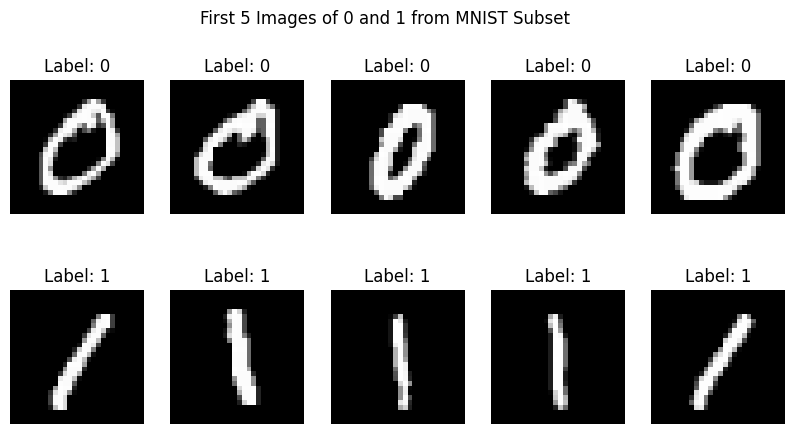

In [10]:
# Separate images for label 0 and label 1
images_0 = X[y == 0]  # Get all images with label 0
images_1 = X[y == 1]  # Get all images with label 1

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

# Check if the arrays have the required amount of data
if len(images_0) < 5 or len(images_1) < 5:
    print("Error: Not enough images in images_0 or images_1 to plot 5 images.")
else:
    for i in range(5):
        # Plot digit 0
        axes[0, i].imshow(images_0[i].reshape(28, 28), cmap="gray")
        axes[0, i].set_title("Label: 0")
        axes[0, i].axis("off")
        # Plot digit 1
        axes[1, i].imshow(images_1[i].reshape(28, 28), cmap="gray")
        axes[1, i].set_title("Label: 1")
        axes[1, i].axis("off")
    plt.suptitle("First 5 Images of 0 and 1 from MNIST Subset")
    plt.show()

## Step - 2 - Initializing the Weights:

In [28]:
# Initialize weights and bias
weights = np.zeros(X.shape[1])  # 784 weights (one for each pixel)
bias = 0
learning_rate = 0.1
epochs = 100

Answer the Following Question:
1. Question - 3: What does the weights array represent in this context?

in the beginning the neural is blind becasue it has not seen any datas and doesnot know which pixel is important

2. Question - 4: Why are we initializing the weights to zero? What effect could this have on the training process?

initializing weights at zero puts models into less stress because it does not know what and how to do. So, starting at zero helps model know the fundamentals and later it progress overtime

## Step - 3 - Make a Decision function:

In [12]:
import numpy as np

def decision_function(X, weights, bias):
    """
    Compute the predicted labels for the input data.

    Parameters:
    - X: Features (input data) as a numpy array of shape (n_samples, n_features)
    - weights: Updated weights after training
    - bias: Updated bias after training

    Returns:
    - y_pred_all: The predicted labels for the input data
    """
    #multiplies pixels by its score and addes them up
    predictions = np.dot(X, weights) + bias
    #####Your Code Here############  # Activation function (step function)
    y_pred_all = np.where(predictions >= 0, 1, 0)

    return y_pred_all

## Step - 3 - Implement the Perceptron Learning Algorithm

In [29]:
def train_perceptron(X, y, weights, bias, learning_rate=0.1, epochs=100):
    """
    Train the perceptron using the Perceptron Learning Algorithm.

    Parameters:
    - X: Features (input data) as a numpy array of shape (n_samples, n_features)
    - y: Labels (true output) as a numpy array of shape (n_samples,)
    - weights: Initial weights as a numpy array of shape (n_features,)
    - bias: Initial bias value (scalar)
    - learning_rate: Learning rate for weight updates (default is 0.1)
    - epochs: Number of iterations to train the model (default is 100)

    Returns:
    - weights: Updated weights after training
    - bias: Updated bias after training
    - accuracy: Total correct prediction.
    """
    # Step 3: Perceptron Learning Algorithm
    # Your Code here#
    n_samples = X.shape[0]

    for epoch in range(epochs):
        accuracy = 0
        for i in range(n_samples):
            #takes raw pixel
            z = np.dot(X[i], weights) + bias

            #activation function
            y_pred = 1 if z >= 0 else 0

            #update weights and bias based on error
            error = y[i] - y_pred
            if error != 0:
                weights += learning_rate * error * X[i]
                bias += learning_rate * error
            else:
                accuracy += 1

        #stops if all samples are classified correctly
        if accuracy == n_samples:
            break
    return weights, bias, accuracy

Answer the Following Question:
1. Question - 5: What is the purpose of the output = np.dot(X[i], weights) + bias line?

It calculates a score for the image by multiplying every pixel by its weight and adding a bias to decide if the neuron should fire

2. Question - 6: What happens when the prediction is wrong? How are the weights and bias updated?

The model calculates the error and nudges the weights and bias increasing them if the prediction was too low and decreasing them if it was too high.


3. Question - 7:Why is the final accuracy important, and what do you expect it to be?

It measures how well the model learned the patterns. for 0s and 1 we should expect 100% accuracy because they look very different

## Training the Perceptron

In [30]:
# After training the model with the perceptron_learning_algorithm
weights, bias, accuracy = train_perceptron(X, y, weights, bias)

# Evaluate the model using the new function
print("The Final Accuracy is: ", accuracy)

The Final Accuracy is:  2696


## Step 5: Visualize Misclassified Images

In [15]:
# Get predictions for all data points
predictions = np.dot(X, weights) + bias
y_pred = np.where(predictions >= 0, 1, 0)

# Calculate final accuracy
final_accuracy = np.mean(y_pred == y)
print(f"Final Accuracy: {final_accuracy:.4f}")

# Step 5: Visualize Misclassified Images
misclassified_idx = np.where(y_pred != y)[0]
if len(misclassified_idx) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(10, 5))
    for ax, idx in zip(axes.flat, misclassified_idx[:10]):  # Show 10 misclassified images
        ax.imshow(X[idx].reshape(28, 28), cmap="gray")
        ax.set_title(f"Pred: {y_pred[idx]}, True: {y[idx]}")
        ax.axis("off")
    plt.suptitle("Misclassified Images")
    plt.show()
else:
    print("All images were correctly classified!")

Final Accuracy: 1.0000
All images were correctly classified!


Answer the Following Question:
1. Question - 8: What does misclassified idx store, and how is it used in this code?

It stores the index positions of the images where the model's prediction didn't match the actual label.

2. Question - 9: How do you interpret the result if the output is ”All images were correctly classified!”?

It means the model achieved 100% accuracy and perfectly separated the 0s from the 1s. This confirms that the two digits are linearly separable meaning their patterns are distinct enough that a single straight decision boundary can tell them apart without any mistakes

Task 3: Perceptron Algorithm for 3 vs 5 Classification.

In [31]:
df_3_5 = pd.read_csv('/content/drive/MyDrive/worksheet3/mnist_3_and_5.csv')

# Extract features and normalize
X = df_3_5.drop(columns=["label"]).values / 255.0
y_raw = df_3_5["label"].values

y = np.where(y_raw == 3, 0, 1)
print(f"Dataset shape: {X.shape}")

Dataset shape: (2741, 784)


In [32]:
weights = np.zeros(X.shape[1])
bias = 0
learning_rate = 0.1
epochs = 100

weights, bias, final_acc_count = train_perceptron(X, y, weights, bias, learning_rate, epochs)

total_samples = len(y)
accuracy_pct = (final_acc_count / total_samples) * 100
print(f"Training Complete. Final Accuracy: {accuracy_pct:.2f}%")

Training Complete. Final Accuracy: 98.36%


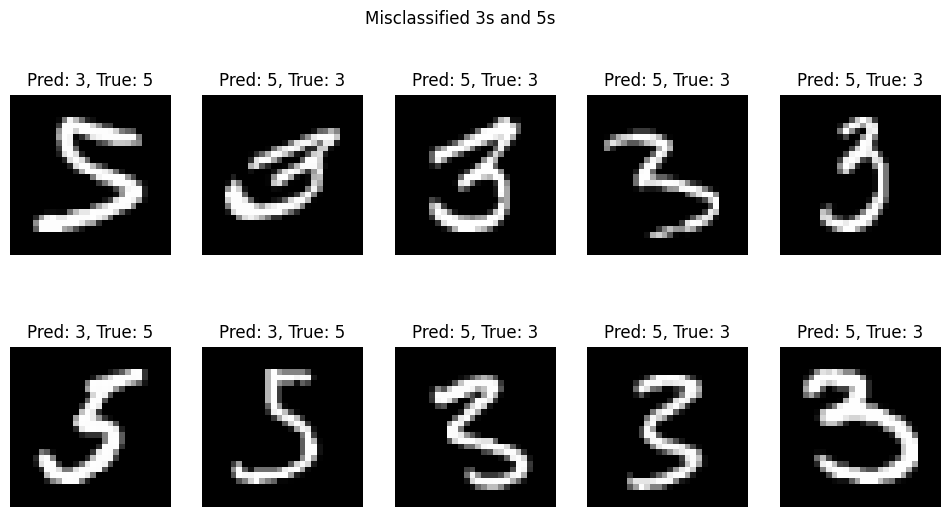

In [18]:
# Get all predictions
y_pred = decision_function(X, weights, bias)

# Find indices where prediction != actual
misclassified_idx = np.where(y_pred != y)[0]

if len(misclassified_idx) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    for ax, idx in zip(axes.flat, misclassified_idx[:10]):
        ax.imshow(X[idx].reshape(28, 28), cmap="gray")
        # Map back to original labels for the title
        actual_label = 3 if y[idx] == 0 else 5
        pred_label = 3 if y_pred[idx] == 0 else 5
        ax.set_title(f"Pred: {pred_label}, True: {actual_label}")
        ax.axis("off")
    plt.suptitle("Misclassified 3s and 5s")
    plt.show()
else:
    print("Perfect classification achieved!")

Visualize the final misclassified images and Provide your conclusion.

the model confuses the 3 and 5 digits becasue they looks identical in bottom loop and middle junction. Errors typically occur when a 3 is drawn with a flat angular top or a 5 lacks a sharp corner, causing their features to overlap in the model's decision space. These highlights the model's high sensitivity to the curvature of the top-left stroke